In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

DATA_DIR = "D:\\ml challenge\\data"



In [63]:
trips = pd.read_csv(f"{DATA_DIR}\\trips_small.csv")
trips.head()


,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993


In [64]:
trips.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993


In [65]:
print(trips.shape)


(1161376, 13)


In [66]:
trips.info()

<class 'pandas.DataFrame'>
RangeIndex: 1161376 entries, 0 to 1161375
Data columns (total 13 columns):
 #   Column            Non-Null Count    Dtype  
---  ------            --------------    -----  
 0   bike_id           1161376 non-null  int64  
 1   city_id           1161376 non-null  int64  
 2   time_start        1161376 non-null  float64
 3   lon_start         1161376 non-null  float64
 4   lat_start         1161376 non-null  float64
 5   lon_end           1161376 non-null  float64
 6   lat_end           1161376 non-null  float64
 7   station_id_start  1072161 non-null  float64
 8   station_id_end    1039472 non-null  float64
 9   battery_start     168532 non-null   float64
 10  battery_end       168641 non-null   float64
 11  duration          1161376 non-null  float64
 12  distance          1161376 non-null  float64
dtypes: float64(11), int64(2)
memory usage: 115.2 MB


In [67]:
trips.isna().sum()


bike_id                  0
city_id                  0
time_start               0
lon_start                0
lat_start                0
lon_end                  0
lat_end                  0
station_id_start     89215
station_id_end      121904
battery_start       992844
battery_end         992735
duration                 0
distance                 0
dtype: int64

the clustering features like time_start , duration and distance doesnot have null values as indicated above so no imputation needed.  Duration column is present so there is no need of computing from start to end time.

null values are being contained by station_id_start     89215
station_id_end      121904
battery_start       992844
battery_end         992735

But the above features doesnot matter as clustering won't depend on them

In [68]:

trips[["duration", "distance","time_start"]].describe()

,duration,distance,time_start
count,1.161376e+06,1.161376e+06,1.161376e+06
mean,1.256241e+03,1.791774e+03,1.676599e+09
std,1.980838e+03,1.495191e+03,9.407677e+06
min,1.210000e+02,5.001365e+01,1.661525e+09
25%,4.800000e+02,8.851685e+02,1.666845e+09
50%,7.200000e+02,1.346711e+03,1.678902e+09
75%,1.200000e+03,2.238540e+03,1.685627e+09
max,2.874000e+04,1.999946e+04,1.689458e+09


Duration:
Median is approx 720  , 720/60=12 minutes
mean= approx 1256 (21min)
as mean above the median means it is rightskewed. small number of long strips
minimum is 121s so under 2 minutes trips were removed
maximum is 28740s far from 75th percentile means long strips are most likely to be outliers

Distance:
median is 1.35km and minimum is 50 m , max is 20km which looks like outliers

In [69]:
trips["city_id"].value_counts()

city_id
848    29661
592    28458
88     28230
530    27232
817    27073
       ...  
811       40
184       39
504       35
308       10
675        1
Name: count, Length: 185, dtype: int64

There are 185 cities.city 848 has almost 29700 trips and 675 has a single trip.

In [70]:
trips["duration"].quantile([0.5, 0.9, 0.95, 0.99, 0.999])


0.500      720.0
0.900     2340.0
0.950     3960.0
0.990    10200.0
0.999    23881.0
Name: duration, dtype: float64

The above tells us about percentage of trips and respective time 


In [71]:
cities = pd.read_csv(f"{DATA_DIR}\\cities.csv", usecols=["id", "timezone"])
cities.head()

,id,timezone
0,220,Europe/Berlin
1,431,Europe/Warsaw
2,199,Europe/Berlin
3,519,Europe/Warsaw
4,21,Europe/Berlin


To get respective timezone of each city we will use reference from cities dataset

adding timezone of each city


In [72]:
trips = trips.merge(cities, left_on="city_id", right_on="id", how="left").drop(columns="id")
trips.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,timezone
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806,Europe/Berlin
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764,Europe/Berlin
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620,Europe/Berlin
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250,Europe/Berlin
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993,Europe/Berlin


In [73]:
utc = pd.to_datetime(trips["time_start"], unit="s", utc=True)
trips.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,timezone
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806,Europe/Berlin
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764,Europe/Berlin
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620,Europe/Berlin
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250,Europe/Berlin
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993,Europe/Berlin


In [74]:
trips["start_dt"] = pd.to_datetime(trips["time_start"], unit="s", utc=True)
trips.head()

,bike_id,city_id,time_start,lon_start,lat_start,lon_end,lat_end,station_id_start,station_id_end,battery_start,battery_end,duration,distance,timezone,start_dt
0,11462,7,1.669377e+09,8.253932,50.069332,8.253393,50.070504,126084480.0,NaN,NaN,NaN,360.0,135.879806,Europe/Berlin,2022-11-25 11:48:01+00:00
1,11462,7,1.669897e+09,8.242628,50.071337,8.216180,50.095700,87796472.0,4775153.0,NaN,NaN,1920.0,3301.514764,Europe/Berlin,2022-12-01 12:21:01+00:00
2,11462,7,1.670252e+09,8.216180,50.095700,8.217791,50.095744,4775153.0,NaN,NaN,NaN,780.0,115.020620,Europe/Berlin,2022-12-05 14:52:01+00:00
3,11462,7,1.670349e+09,8.226448,50.076546,8.249343,50.078160,4775087.0,87796883.0,NaN,NaN,540.0,1643.609250,Europe/Berlin,2022-12-06 17:43:01+00:00
4,11462,7,1.671514e+09,8.249343,50.078160,8.242628,50.071337,87796883.0,87796472.0,NaN,NaN,4680.0,897.351993,Europe/Berlin,2022-12-20 05:28:01+00:00


In [75]:
trips["timezone"].isna().sum()

np.int64(0)

To convert to local timezone

In [76]:
trips["start_hour"] = 0.0
trips["is_weekend"] = False

for tz, idx in trips.groupby("timezone").groups.items():
    local = trips.loc[idx, "start_dt"].dt.tz_convert(tz)
    trips.loc[idx, "start_hour"] = local.dt.hour + local.dt.minute / 60
    trips.loc[idx, "is_weekend"] = local.dt.dayofweek >= 5

trips[["start_hour", "is_weekend", "duration"]].describe()


,start_hour,duration
count,1.161376e+06,1.161376e+06
mean,1.432396e+01,1.256241e+03
std,5.131749e+00,1.980838e+03
min,0.000000e+00,1.210000e+02
25%,1.066667e+01,4.800000e+02
50%,1.495000e+01,7.200000e+02
75%,1.816667e+01,1.200000e+03
max,2.398333e+01,2.874000e+04


Datetime holds date and time together and for clustering on basis of start time we need start hour so we extracted start hour
Describe tells us that start hour is from 0 to 23.98
half of the trips start between about 10:40 am and 6:10 pm from 25th% and 75th% rows and median about 3pm

Now removing duration outliers and split into weekend and weekdays so kmeans works perfectly

Droping extreme 1% and keeping rest

In [77]:
cap=trips["duration"].quantile(0.99)
trips=trips[trips["duration"] <= cap]
print(cap, trips.shape)

10200.0 (1149774, 17)


splitting the data

In [78]:
weekday = trips[~trips["is_weekend"]]# select that are not weekened
weekend = trips[trips["is_weekend"]] # select that are only weekend
print(weekday.shape, weekend.shape)


(886268, 17) (263506, 17)


In [79]:
weekday["duration"].describe(), weekend["duration"].describe()


(count    886268.000000
 mean       1055.392019
 std        1206.897794
 min         121.000000
 25%         420.000000
 50%         660.000000
 75%        1140.000000
 max       10200.000000
 Name: duration, dtype: float64,
 count    263506.000000
 mean       1293.803340
 std        1393.411037
 min         121.000000
 25%         540.000000
 50%         840.000000
 75%        1440.000000
 max       10200.000000
 Name: duration, dtype: float64)

There are more weekdays trips then weekend. Weekends trips are longer as indicated by 25th% and 75th% and median(14 vs 12min) . the mean is still above the median in bith groups means right skewed, but sd drops than before

Scaling by start time

In [ ]:
features = ["start_hour"]

scaler_wd = StandardScaler()
X_weekday = scaler_wd.fit_transform(weekday[features])

scaler_we = StandardScaler()
X_weekend = scaler_we.fit_transform(weekend[features])

X_weekday.shape, X_weekend.shape

In [81]:
X_weekday.mean(axis=0), X_weekday.std(axis=0)


(array([ 3.69434632e-17, -9.44110727e-17]), array([1., 1.]))

### Clustering by start time

In [83]:

def try_k(X, ks=range(2, 9), sample=20000):
    inertias, sils = [], []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
        inertias.append(km.inertia_)
        sils.append(silhouette_score(X, km.labels_, sample_size=sample, random_state=42))
    return list(ks), inertias, sils


In [84]:
ks, inertia_wd, sil_wd = try_k(X_weekday)
ks, inertia_we, sil_we = try_k(X_weekend)


In [ ]:
def plot_k_grid(df, X, scaler, name, ks=range(2, 9)):
    hours = df["start_hour"].to_numpy()
    bins = np.arange(0, 24.25, 0.25)
    cmap = plt.get_cmap("tab10")

    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    axes = axes.ravel()

    for ax, k in zip(axes, ks):
        km = KMeans(n_clusters=k, n_init=3, random_state=42).fit(X)
        centers = scaler.inverse_transform(km.cluster_centers_).ravel()
        rank = np.argsort(np.argsort(centers))
        labels = rank[km.labels_]

        ax.hist([hours[labels == c] for c in range(k)], bins=bins, stacked=True,
                color=[cmap(c) for c in range(k)])

        sorted_centers = np.sort(centers)
        for b in (sorted_centers[:-1] + sorted_centers[1:]) / 2:
            ax.axvline(b, color="black", linestyle="--", linewidth=0.8)

        ax.set_title(f"k = {k}")
        ax.set_xlabel("Start hour")
        ax.set_ylabel("trips")
        ax.set_xticks(range(0, 25, 6))

    for ax in axes[len(ks):]:
        ax.axis("off")

    fig.suptitle(f"{name} trips: start time clusters for each k", fontsize=14)
    plt.tight_layout()
    plt.show()

plot_k_grid(weekday, X_weekday, scaler_wd, "Weekday")
plot_k_grid(weekend, X_weekend, scaler_we, "Weekend")

In [86]:
print("k  | weekday inertia, silhouette | weekend inertia, silhouette")
for k, iw, sw, ie, se in zip(ks, inertia_wd, sil_wd, inertia_we, sil_we):
    print(k, "|", round(iw), round(sw, 3), "|", round(ie), round(se, 3))


k  | weekday inertia, silhouette | weekend inertia, silhouette
2 | 1150982 0.442 | 344748 0.57
3 | 572697 0.496 | 179286 0.47
4 | 445731 0.399 | 129301 0.422
5 | 336455 0.421 | 94764 0.449
6 | 292274 0.367 | 79264 0.387
7 | 255159 0.378 | 68350 0.389
8 | 222857 0.391 | 60598 0.399


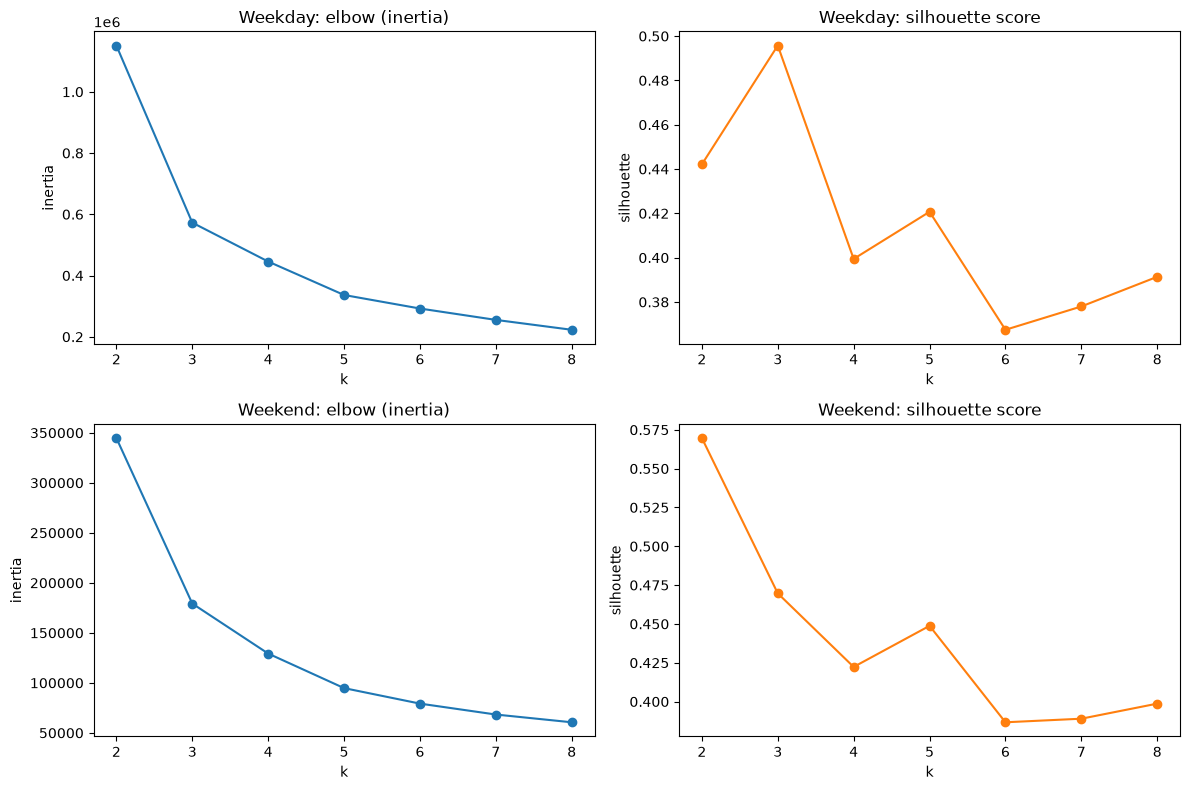

In [87]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (name, inertia, sil) in enumerate([("Weekday", inertia_wd, sil_wd),
                                            ("Weekend", inertia_we, sil_we)]):
    axes[row, 0].plot(ks, inertia, marker="o")
    axes[row, 0].set_title(f"{name}: elbow (inertia)")
    axes[row, 0].set_xlabel("k")
    axes[row, 0].set_ylabel("inertia")

    axes[row, 1].plot(ks, sil, marker="o", color="tab:orange")
    axes[row, 1].set_title(f"{name}: silhouette score")
    axes[row, 1].set_xlabel("k")
    axes[row, 1].set_ylabel("silhouette")

plt.tight_layout()
plt.show()


Weekdays:
Elbow(inertia): after k=3 the curve bend slowly so that means elbow is at 3
Silhouette: the peak is at k=3 and then stays low
both method agreed on k=3 means 3 clusters

Weekends:
Elbow:The big drop is from k=2 to 3 and afer 3 it drops slowly
Silhouette : It is highest at k=2 and after that it stays low
So both methods points slightly different like elbow says 3 and silhouette says 2
let take k=3 (supporting by elbow) in this way we can compare weekday and weekly pattern as well

In [90]:
k_wd, k_we = 3, 3

km_wd = KMeans(n_clusters=k_wd, n_init=10, random_state=42).fit(X_weekday)
km_we = KMeans(n_clusters=k_we, n_init=10, random_state=42).fit(X_weekend)

weekday = weekday.assign(cluster=km_wd.labels_)
weekend = weekend.assign(cluster=km_we.labels_)


In [ ]:
for name, df in [("Weekday", weekday), ("Weekend", weekend)]:
    print(name)
    print(df.groupby("cluster").agg(trips=("start_hour", "size"),
                                    start_hour=("start_hour", "mean"),
                                    hour_from=("start_hour", "min"),
                                    hour_to=("start_hour", "max")).round(1))

### Clustering by duration

AS duration as 0 null values. Duration is in seconds min=121s. Trips over 99th percentile were removed as outlier cap. Data is split in weekdays and weekends. Obs is median is 14mins vs 11 mins and that is the reason we cluster groups separately

With one feature kmeans finds the cut points with single line. Duration is right skewed as median 11 vs 14mins and tail 2.8hrs. So we  before deciding for log transform before clustering we need to see shape first

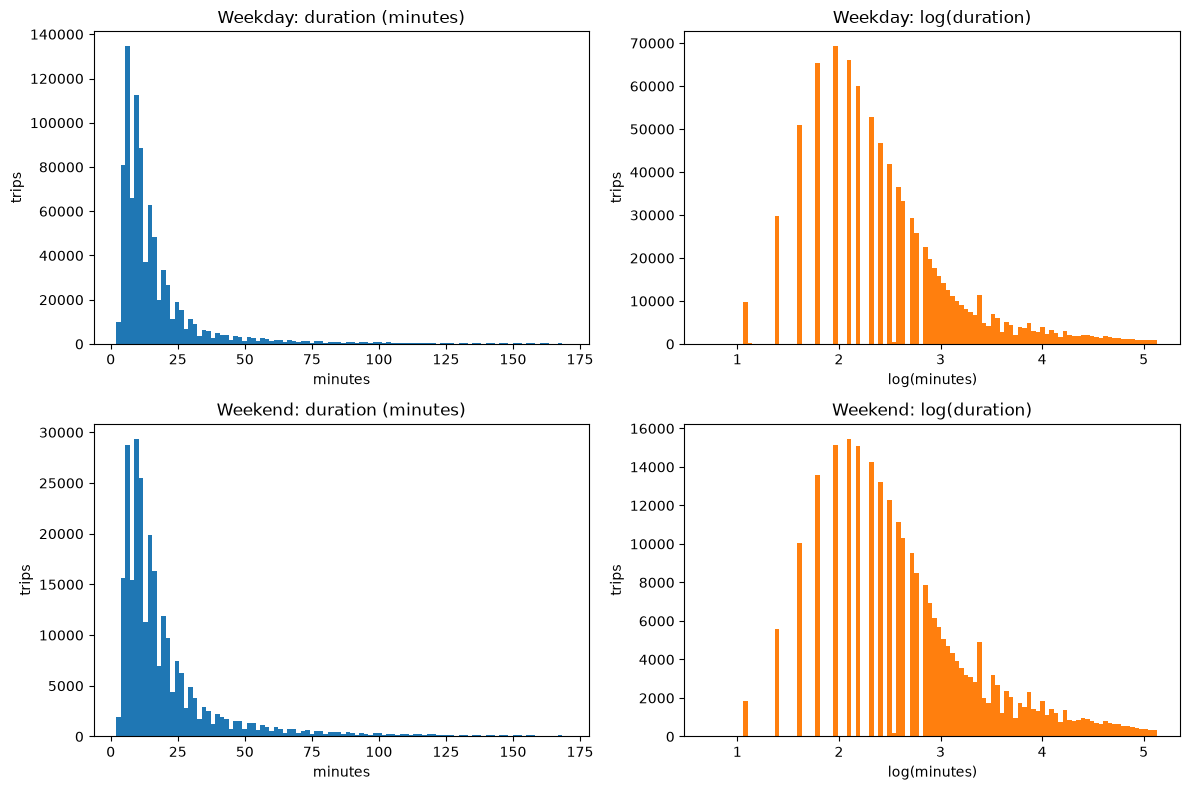

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (name, df) in enumerate([("Weekday", weekday), ("Weekend", weekend)]):
    minutes = df["duration"] / 60

    axes[row, 0].hist(minutes, bins=100, color="tab:blue")
    axes[row, 0].set_title(f"{name}: duration (minutes)")
    axes[row, 0].set_xlabel("minutes")
    axes[row, 0].set_ylabel("trips")

    axes[row, 1].hist(np.log(minutes), bins=100, color="tab:orange")
    axes[row, 1].set_title(f"{name}: log(duration)")
    axes[row, 1].set_xlabel("log(minutes)")
    axes[row, 1].set_ylabel("trips")

plt.tight_layout()
plt.show()


Duration is right skewed as it can be seen. most trips are upto 5-15mins. Weekends trips are a bit longer .By taking log , it reduces the skew and spread the short trips.

The log spreads out the small duration trips region and it pulls in the tail this will help in kmeans getting more usefull cut points

After log , we are making data Standardize, it will kepp the numbers on same scale while clustering

In [93]:
dur_features = {}
dur_scalers = {}

for name, df in [("weekday", weekday), ("weekend", weekend)]:
    log_min = np.log(df["duration"] / 60).to_numpy().reshape(-1, 1)
    scaler = StandardScaler()
    dur_features[name] = scaler.fit_transform(log_min)
    dur_scalers[name] = scaler

for name, X in dur_features.items():
    print(name, X.shape, X.mean().round(3), X.std().round(3))


weekday (886268, 1) 0.0 1.0
weekend (263506, 1) -0.0 1.0


Observation is mean 0 and sd 1 

Applying Kmeans

In [94]:
ks, dur_inertia_wd, dur_sil_wd = try_k(dur_features["weekday"])
ks, dur_inertia_we, dur_sil_we = try_k(dur_features["weekend"])


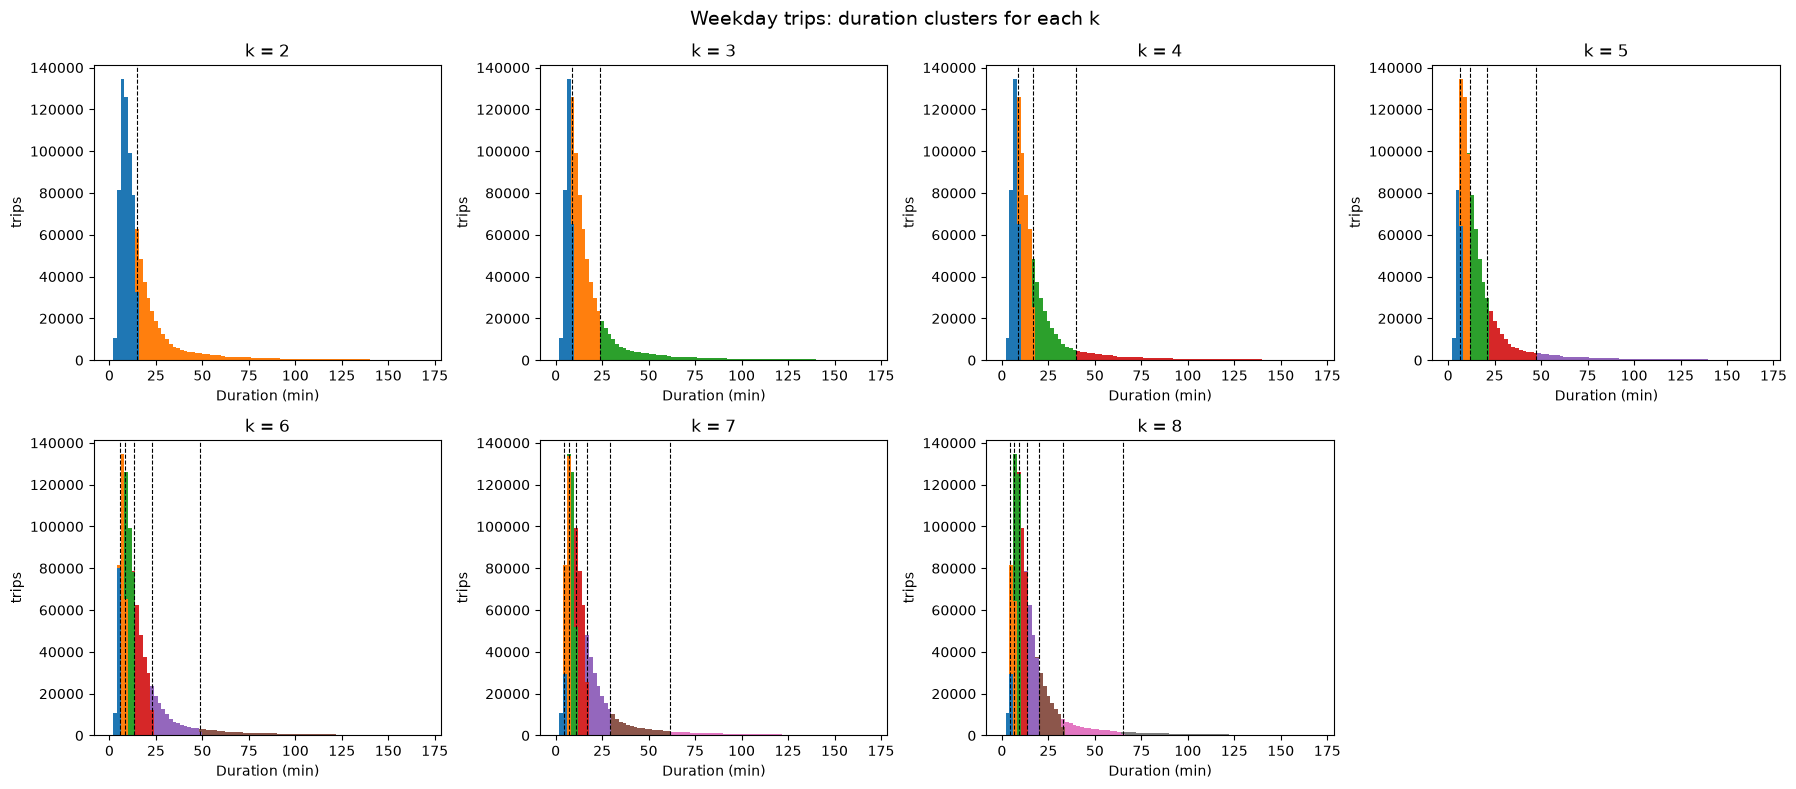

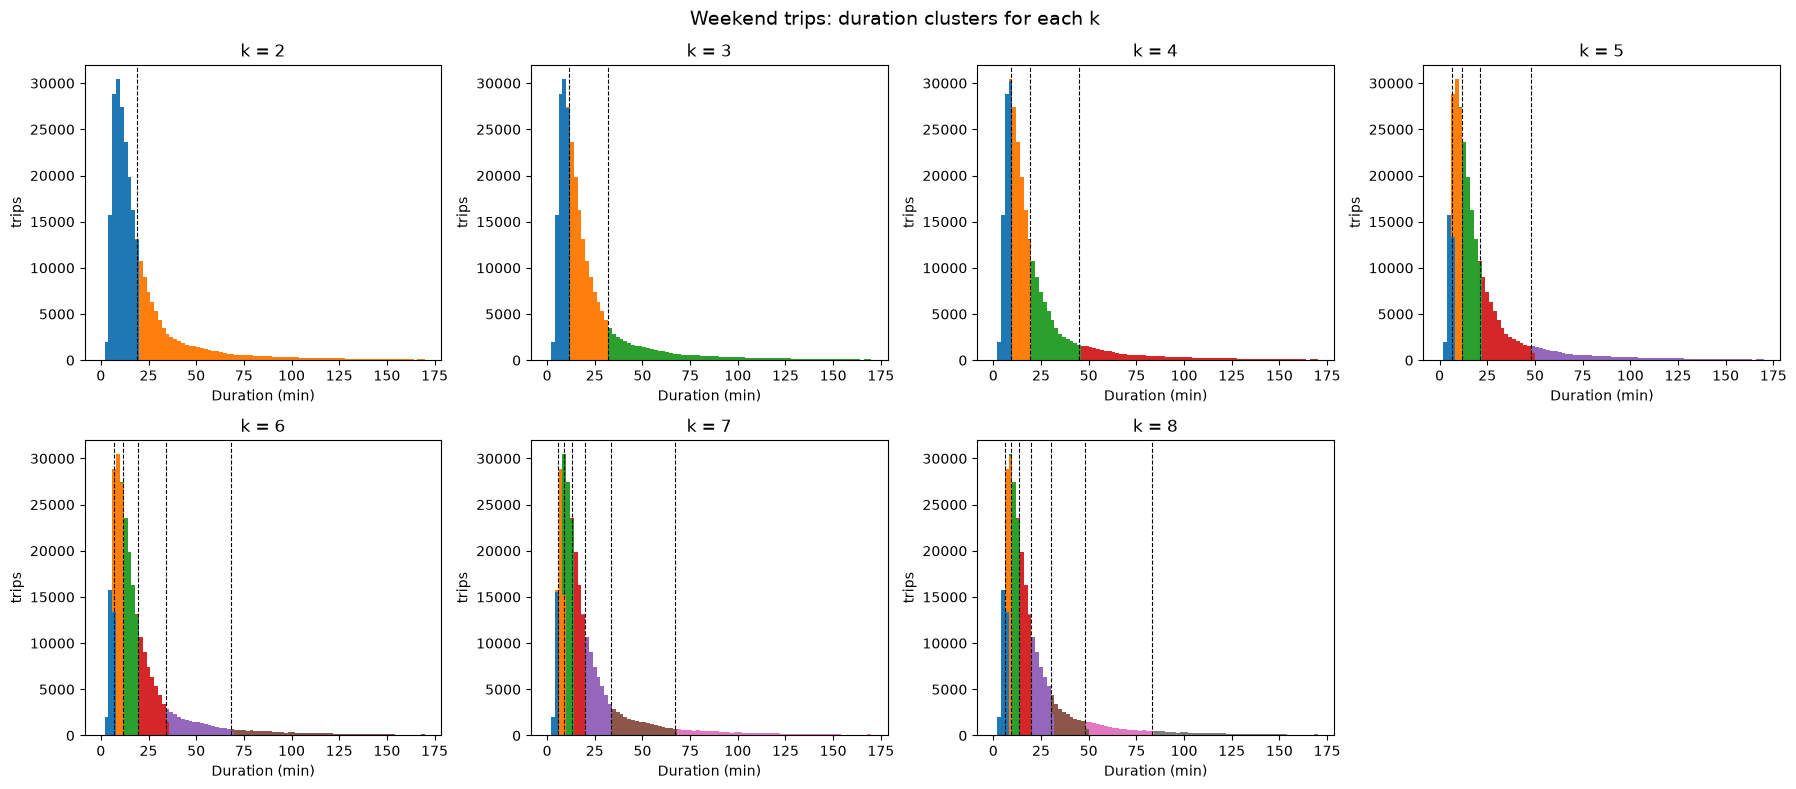

In [99]:
def plot_dur_k_grid(df, X, scaler, name, ks=range(2, 9)):
    minutes = (df["duration"] / 60).to_numpy()
    bins = np.arange(0, 171, 2)
    cmap = plt.get_cmap("tab10")

    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    axes = axes.ravel()

    for ax, k in zip(axes, ks):
        km = KMeans(n_clusters=k, n_init=3, random_state=42).fit(X)
        centers = np.exp(scaler.inverse_transform(km.cluster_centers_).ravel())
        rank = np.argsort(np.argsort(centers))
        labels = rank[km.labels_]

        ax.hist([minutes[labels == c] for c in range(k)], bins=bins, stacked=True,
                color=[cmap(c) for c in range(k)])

        sorted_centers = np.sort(centers)
        for b in np.sqrt(sorted_centers[:-1] * sorted_centers[1:]):
            ax.axvline(b, color="black", linestyle="--", linewidth=0.8)

        ax.set_title(f"k = {k}")
        ax.set_xlabel("Duration (min)")
        ax.set_ylabel("trips")

    for ax in axes[len(ks):]:
        ax.axis("off")

    fig.suptitle(f"{name} trips: duration clusters for each k", fontsize=14)
    plt.tight_layout()
    plt.show()

plot_dur_k_grid(weekday, dur_features["weekday"], dur_scalers["weekday"], "Weekday")
plot_dur_k_grid(weekend, dur_features["weekend"], dur_scalers["weekend"], "Weekend")


In [95]:
print("k  | weekday inertia, silhouette | weekend inertia, silhouette")
for k, iw, sw, ie, se in zip(ks, dur_inertia_wd, dur_sil_wd, dur_inertia_we, dur_sil_we):
    print(k, "|", round(iw), round(sw, 3), "|", round(ie), round(se, 3))


k  | weekday inertia, silhouette | weekend inertia, silhouette
2 | 328457 0.58 | 94306 0.57
3 | 159768 0.559 | 45463 0.554
4 | 94057 0.545 | 26881 0.543
5 | 62445 0.546 | 18117 0.537
6 | 44771 0.554 | 12704 0.54
7 | 32136 0.559 | 9445 0.551
8 | 25430 0.574 | 7326 0.563


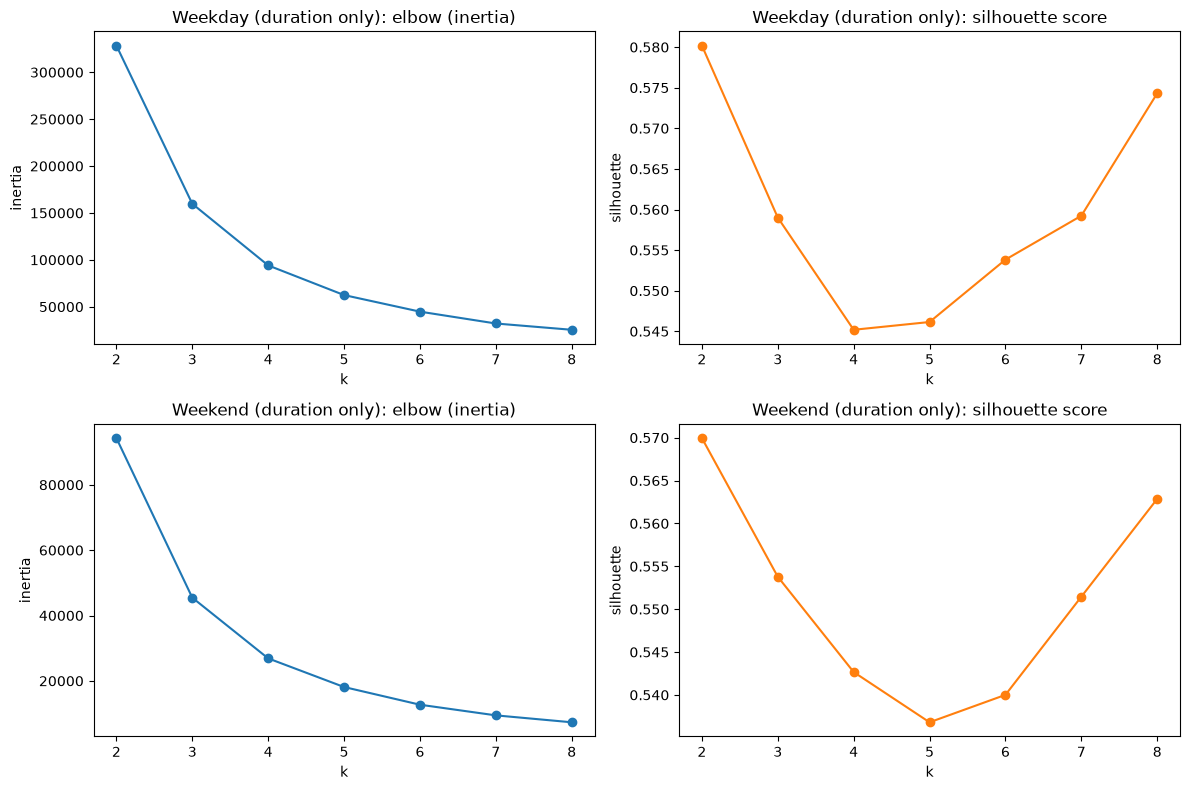

In [96]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, (name, inertia, sil) in enumerate([("Weekday", dur_inertia_wd, dur_sil_wd),
                                            ("Weekend", dur_inertia_we, dur_sil_we)]):
    axes[row, 0].plot(ks, inertia, marker="o")
    axes[row, 0].set_title(f"{name} (duration only): elbow (inertia)")
    axes[row, 0].set_xlabel("k")
    axes[row, 0].set_ylabel("inertia")

    axes[row, 1].plot(ks, sil, marker="o", color="tab:orange")
    axes[row, 1].set_title(f"{name} (duration only): silhouette score")
    axes[row, 1].set_xlabel("k")
    axes[row, 1].set_ylabel("silhouette")

plt.tight_layout()
plt.show()


Elbow method shows that the curve bends at k=3 in both weekends and weekdays. The silhouette score range is between 0.54 to 0.58 in bith weekend and weekdays showing barely vary with k. Hence we choose k=3.

In [97]:
dur_k = 3
results = {}

for name, df in [("weekday", weekday), ("weekend", weekend)]:
    km = KMeans(n_clusters=dur_k, n_init=10, random_state=42).fit(dur_features[name])
    centers = np.exp(dur_scalers[name].inverse_transform(km.cluster_centers_).ravel())
    rank = np.argsort(np.argsort(centers))
    results[name] = (df.assign(dur_cluster=rank[km.labels_]), np.sort(centers))

weekday = results["weekday"][0]
weekend = results["weekend"][0]


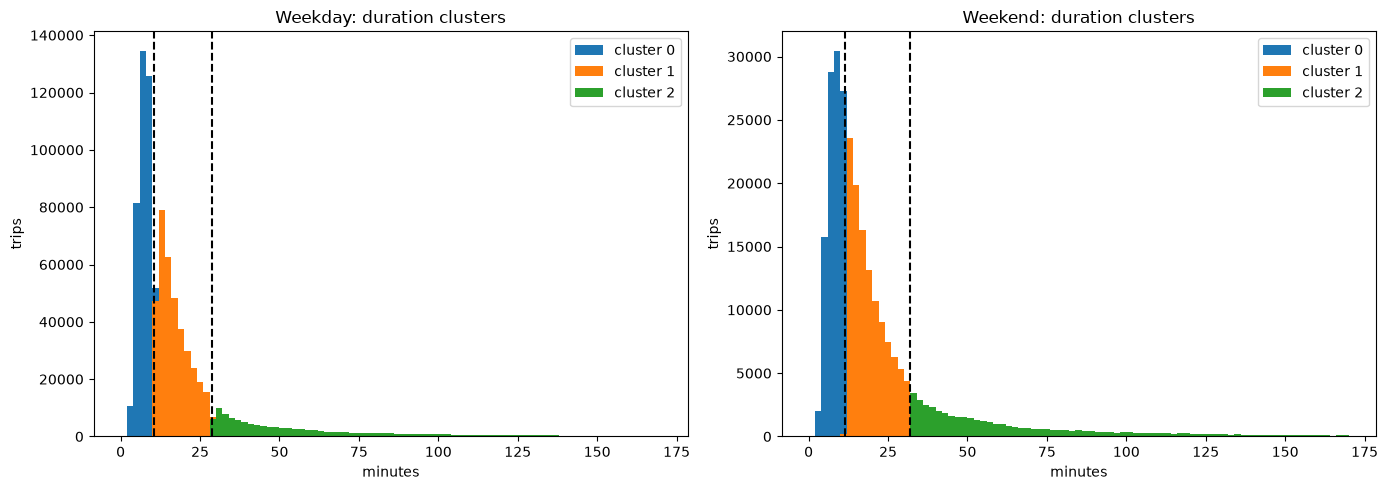

In [98]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ["tab:blue", "tab:orange", "tab:green"]

for ax, (name, df) in zip(axes, [("weekday", weekday), ("weekend", weekend)]):
    minutes = df["duration"] / 60
    centers = results[name][1]
    bounds = np.sqrt(centers[:-1] * centers[1:])

    for c in range(dur_k):
        ax.hist(minutes[df["dur_cluster"] == c], bins=np.arange(0, 171, 2),
                color=colors[c], label=f"cluster {c}")
    for b in bounds:
        ax.axvline(b, color="black", linestyle="--")

    ax.set_title(f"{name.capitalize()}: duration clusters")
    ax.set_xlabel("minutes")
    ax.set_ylabel("trips")
    ax.legend()

plt.tight_layout()
plt.show()
